# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *
from sources.finitevolume import *

# Generate data

In [2]:
X_r, X_data, u_data = gen_train_data(60_000,20_000,20_000)

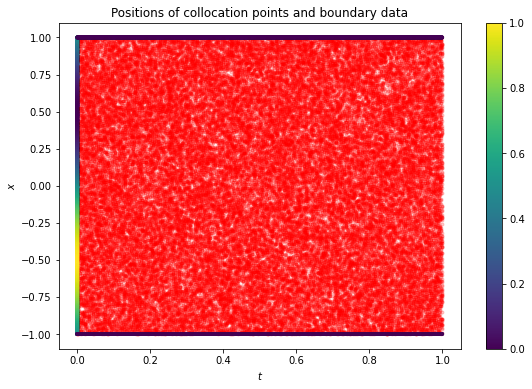

In [3]:
plot_train_data(X_r, X_data, u_data)

# Training

In [4]:
model = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=16, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))

solver = PINNSolver2(model, batch_size = 10_000, weight_filename = 'reduced_model.h5')

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=100,
    decay_rate=0.97,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 1.)
  solver.solve_with_ScipyOptimizer(X_r, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('burgers')

Epoch 19_900: phi_r  1.2418e-04    phi_0  2.0144e-06    phi_b  6.9910e-06    total_loss  1.3318e-04
Training time: 6629.546486377716 seconds


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

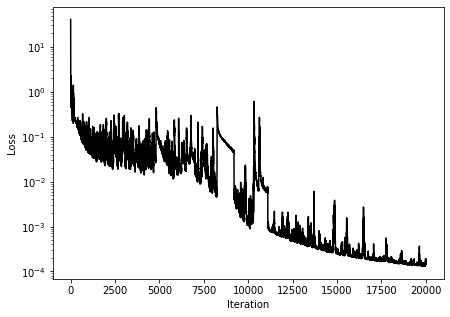

In [5]:
solver.plot_loss_history()

# Check results

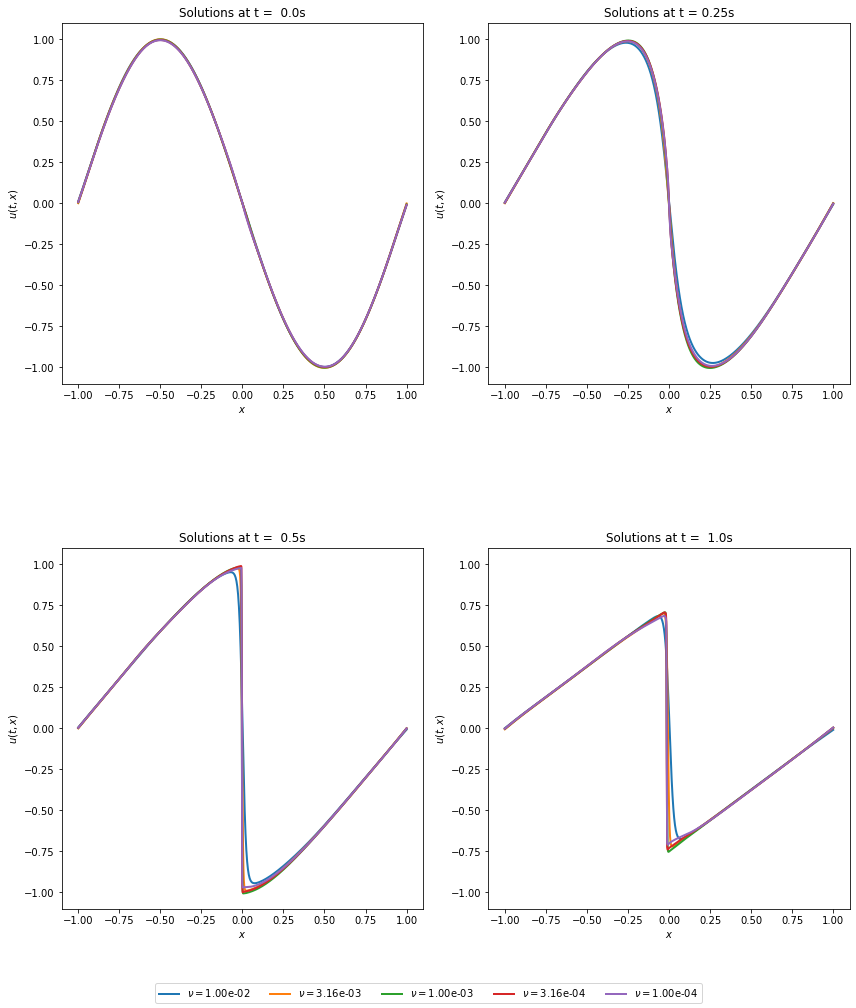

In [6]:
N = 800

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12,15))
axs = axs.flatten()

all_times = [0., 0.25, 0.5, 1.0]

for i,end_time in enumerate(all_times):
    
    for visc in np.logspace(-2, -4, 5):

      # solution en utilisant le PINN
      xspace = np.linspace(-1,1,N)
      T, X = np.meshgrid(end_time, xspace)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(), X.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      axs[i].plot(xspace, upred, '-', linewidth = 2, label=r'$\nu=${:4.2e}'.format(visc))

      axs[i].set_xlabel('$x$')
      axs[i].set_ylabel('$u(t,x)$')    
      axs[i].axis('square')
      axs[i].set_xlim([-1.1,1.1])
      axs[i].set_ylim([-1.1,1.1]);
      axs[i].set_title('Solutions at t = {:4.2}s'.format(end_time));


handles, labels = axs[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5);
fig.tight_layout()
#plt.savefig('./figures/Burgers{:03d}'.format(i), bbox_inches = 'tight')

# Compare with exact solution

In [2]:
model = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=16, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))
model.load_weights(WEIGHT_PATH + 'reduced_model.h5')

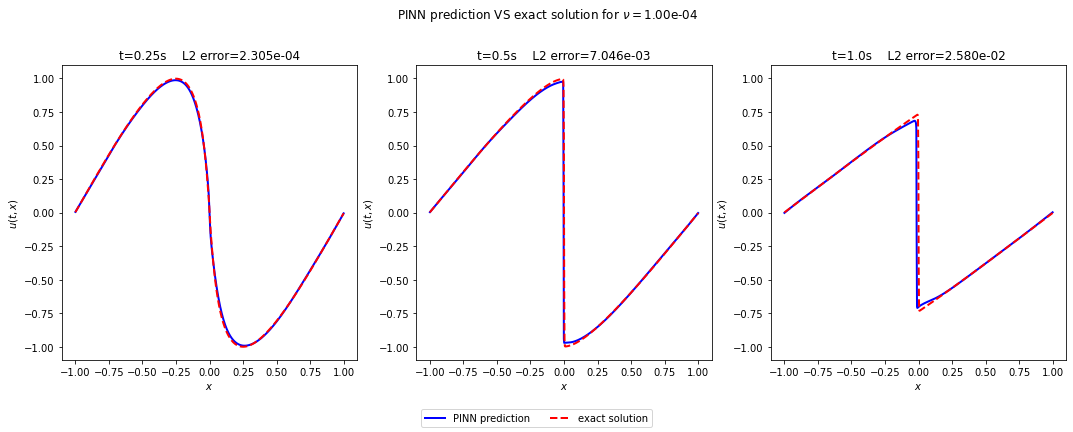

In [6]:
N = 800
visc = 1e-4

bg=EDP(N, visc, u_0)
x = bg.cells[bg.begin:bg.end]

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

all_times = [0.25, 0.5, 1.0]
for i_t, end_time in enumerate(all_times):

  bg.init()
  sol=bg.solve(end_time)
  exact_sol = sol[-1]

  # solution en utilisant le PINN
  T, X = np.meshgrid(end_time, x)
  nuspace = visc * np.ones(N)
  Xgrid = np.vstack([T.flatten(),x.flatten(), nuspace.flatten()]).T
  upred = model(tf.cast(Xgrid,DTYPE))
  upred = tf.reshape(upred, (1,N))[0].numpy()

  # affichage
  erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
  title = "t={}s    L2 error={:5.3e}".format(end_time, erreurL2)
  ax[i_t].set_title(title)

  ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
  ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

  ax[i_t].set_xlabel('$x$')
  ax[i_t].set_ylabel('$u(t,x)$')    
  ax[i_t].axis('square')
  ax[i_t].set_xlim([-1.1,1.1])
  ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2);
plt.suptitle(r"PINN prediction VS exact solution for $\nu=${:4.2e}".format(visc));